# Interactive demo: Gras's algorithm and the optimized algorithm

Oriented hierarchies in statistical implicative analysis (SIA): this notebook runs **Gras's algorithm** and the **optimized algorithm** on the simulated datasets of the repository.

To stay fast in the browser, it uses the small datasets `simulation_1.csv` to `simulation_8.csv` (from 10 to 80 variables). The full experiments on `simulation_19.csv` (190 variables) are in `Gras_Algorithm.ipynb` and `Optimized_Algorithm.ipynb`.

Associated publication: *Combinatorial and Algorithmic Analysis of Oriented Hierarchies in Implicative Statistical Analysis*, Annals of Mathematics and Artificial Intelligence (Springer Nature).

Run the cells from top to bottom (menu *Runtime → Run all* on Colab). Running times depend on the machine.

In [1]:
# Setup: get the repository code if the notebook is opened outside the repo (e.g. on Colab)
import os, subprocess

REPO = "Gras-algorithm-for-constructing-an-oriented-hierarchy"
URL = "https://github.com/Fidy-Heritiana/" + REPO + ".git"

if not os.path.exists("sia_algorithms.py"):
    subprocess.run(["git", "clone", URL], check=True)
    os.chdir(REPO)

print("Repository code ready.")

Repository code ready.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

import sia_algorithms as sia

## 1. Choose a dataset and a threshold

`numero` selects `simulation_<numero>.csv` (1 to 8). `alpha` is the threshold of the optimized algorithm: there is an arrow i → j when the implication intensity of i ⇒ j is greater than `alpha`.

In [3]:
numero = 3
alpha = 0.85

fichier = f"simulation_{numero}.csv"
df = pd.read_csv(fichier)
print(fichier, ":", df.shape[0], "observations,", df.shape[1], "variables")
df.head()

simulation_3.csv : 130 observations, 30 variables


,Var1,Var2,Var3,Var4,Var5,Var6,Var7,Var8,Var9,Var10,...,Var21,Var22,Var23,Var24,Var25,Var26,Var27,Var28,Var29,Var30
0,0,1,1,1,1,0,1,1,1,0,...,1,1,0,1,0,1,0,1,1,1
1,1,0,0,0,0,0,1,1,0,0,...,0,1,0,0,0,1,1,0,1,1
2,1,1,0,0,1,0,1,0,0,1,...,0,0,0,0,0,0,0,1,1,0
3,1,1,0,0,1,0,0,1,0,1,...,0,1,0,1,1,1,1,1,0,1
4,0,0,0,0,0,1,1,1,1,0,...,0,0,0,0,0,1,0,0,0,1


## 2. Run both algorithms

The times below are those of the algorithms themselves, without the construction of the implication matrix.

In [4]:
mat_gras = sia.matrice_implication(df, "gras")
h, t_gras = sia.chronometre(sia.gras_hierarchy, mat_gras)
# the loop of the notebook appends its last class a second time: each class is kept once here
h = list(dict.fromkeys(tuple(c) for c in h))

mat_opt = sia.matrice_implication(df, "optimized")
(G, hier), t_opt = sia.chronometre(sia.optimized_hierarchy, mat_opt, alpha)

def au_moins_2(classes):
    return [c for c in classes if len(c) >= 2]

print(f"Gras      : {len(h)} classes ({len(au_moins_2(h))} with at least 2 variables) in {t_gras:.3f} s")
print(f"Optimized : {len(hier)} classes ({len(au_moins_2(hier))} with at least 2 variables) in {t_opt:.3f} s")
if t_opt > 0:
    print(f"The optimized algorithm is about {t_gras / t_opt:.0f} times faster on this dataset.")

Gras      : 48 classes (18 with at least 2 variables) in 0.313 s
Optimized : 36 classes (6 with at least 2 variables) in 0.015 s
The optimized algorithm is about 22 times faster on this dataset.


## 3. The classes with at least two variables

A class of Gras's algorithm is an *ordered* chain of variables; a class of the optimized algorithm is listed with its variables sorted.

In [5]:
def afficher(classes, titre, maxi=15, fleche=" → "):
    liste = au_moins_2(classes)
    print(f"{titre} ({len(liste)} classes with at least 2 variables)")
    for c in liste[:maxi]:
        print("  ", fleche.join(str(v) for v in c))
    if len(liste) > maxi:
        print(f"   ... and {len(liste) - maxi} more")

afficher(h, "Gras")
print()
afficher(hier, "Optimized", fleche=", ")

Gras (18 classes with at least 2 variables)
   Var21 → Var23
   Var6 → Var9
   Var19 → Var1
   Var26 → Var6 → Var9
   Var3 → Var29
   Var30 → Var22
   Var5 → Var8
   Var21 → Var23 → Var4
   Var27 → Var11
   Var25 → Var24
   Var27 → Var11 → Var17
   Var12 → Var3 → Var29
   Var13 → Var30 → Var22
   Var10 → Var28
   Var18 → Var20
   ... and 3 more

Optimized (6 classes with at least 2 variables)
   Var1, Var19
   Var6, Var9
   Var29, Var3
   Var21, Var23
   Var26, Var6
   Var26, Var6, Var9


## 4. Implication graph (optimized algorithm)

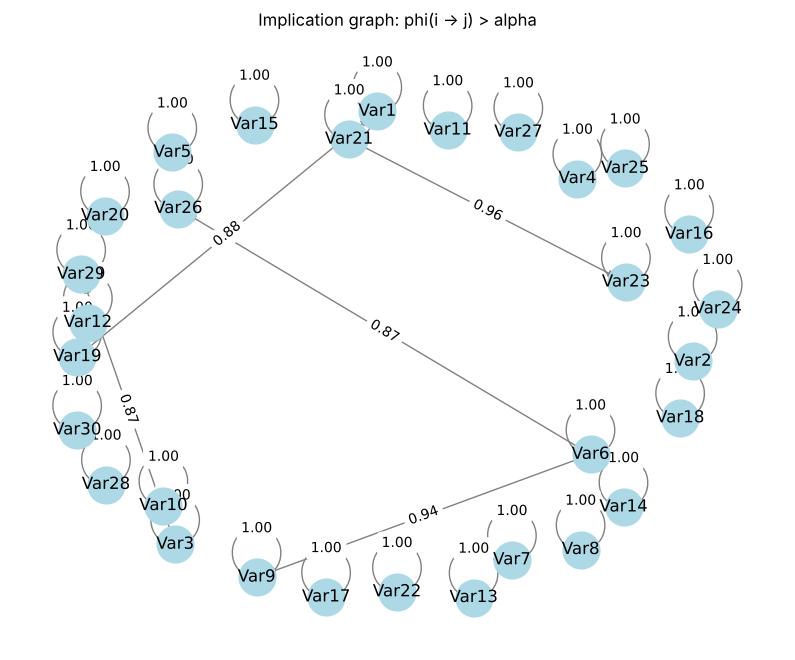

In [6]:
if 0 < G.number_of_nodes() <= 40:
    sia.dessiner_graphe(G)
    plt.show()
elif G.number_of_nodes() == 0:
    print("No arrow for this threshold: try a smaller alpha.")
else:
    print(f"The graph has {G.number_of_nodes()} vertices: too many to draw here. Try a smaller dataset.")

## 5. Running time against the number of variables

Both algorithms on `simulation_1.csv` to `simulation_6.csv` (10 to 60 variables), with the same threshold.

,variables,Gras (s),Optimized (s)
0,10,0.010,0.003
1,20,0.102,0.007
2,30,0.332,0.014
3,40,0.639,0.024
4,50,1.777,0.035
5,60,2.943,0.058


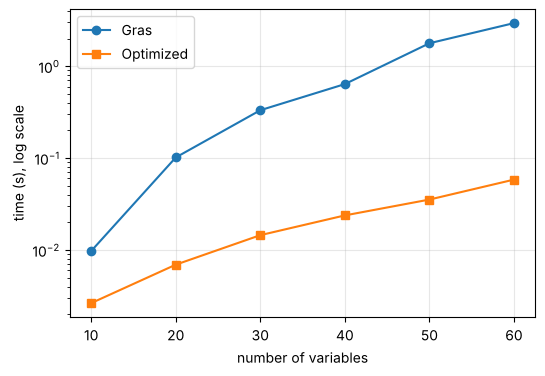

In [7]:
lignes = []
for k in range(1, 7):
    d = pd.read_csv(f"simulation_{k}.csv")
    _, tg = sia.chronometre(sia.gras_hierarchy, sia.matrice_implication(d, "gras"))
    _, to = sia.chronometre(sia.optimized_hierarchy, sia.matrice_implication(d, "optimized"), alpha)
    lignes.append({"variables": d.shape[1], "Gras (s)": tg, "Optimized (s)": to})

temps = pd.DataFrame(lignes)
display(temps.round(3))

plt.figure(figsize=(6, 4))
plt.plot(temps["variables"], temps["Gras (s)"], marker="o", label="Gras")
plt.plot(temps["variables"], temps["Optimized (s)"], marker="s", label="Optimized")
plt.yscale("log")
plt.xlabel("number of variables")
plt.ylabel("time (s), log scale")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 6. Interactive version

Choose a dataset and a threshold, then press the button. Buttons and sliders do not display in the GitHub preview: open this notebook on Colab or Binder to use them.

In [ ]:
_cache = {}

def run_demo(numero=3, alpha=0.85):
    d = pd.read_csv(f"simulation_{numero}.csv")
    if numero not in _cache:   # Gras does not depend on alpha: compute it once per dataset
        hh, t = sia.chronometre(sia.gras_hierarchy, sia.matrice_implication(d, "gras"))
        _cache[numero] = (list(dict.fromkeys(tuple(c) for c in hh)), t)
    hh, t_gras = _cache[numero]

    (GG, hier), t_opt = sia.chronometre(
        sia.optimized_hierarchy, sia.matrice_implication(d, "optimized"), alpha
    )
    print(f"simulation_{numero}.csv: {d.shape[1]} variables, alpha = {alpha}")
    print(f"Gras      : {len(hh)} classes in {t_gras:.3f} s")
    print(f"Optimized : {len(hier)} classes in {t_opt:.3f} s")
    if 0 < GG.number_of_nodes() <= 40:
        sia.dessiner_graphe(GG)
        plt.show()


try:
    from ipywidgets import interact_manual, IntSlider, FloatSlider
    interact_manual(
        run_demo,
        numero=IntSlider(min=1, max=8, step=1, value=3),
        alpha=FloatSlider(min=0.5, max=0.99, step=0.01, value=0.85),
    )
except ImportError:
    run_demo()